# Лабораторна робота 4

**Виконав:** Бугайчук Василь 

**Група:** КМ-51
# Мета роботи:

Розробити програмний засіб, який здійснює центральну проєкцію зображення на одній площині та відображує її на іншій площині і зберігає зображення в одному з графічних форматів.



 

# Хід роботи

- Дослідити математичні методи перспективних проєкцій.

- Використати перетворений датасет з лабораторної роботи №3 поклавши координату z = 100

- Скачати файл з датасетом. Файл в текстовому форматі містить пари цілих чисел які є координатами точок. 

# Необхідно написати програму будь якою мовою з використанням будь яких бібліотек яка:

1. Зчитує датасет з файлу;
2. Знаходить матрицю центральної проекції з точкою сходження (540; 960)
3. Розраховує новий датасет зпроектованої площини 
4. Встановлює розміри вікна (полотна – canvas size) 960х540пкс;
5. Відображає новий датасет;
6. Виводить результати у файли будь-якого графічного формату.

Матриця центральної проєкції:
   500.000      0.000    540.000      0.000
     0.000    500.000    960.000      0.000
     0.000      0.000      0.000      0.000
     0.000      0.000      1.000    500.000
Центр проєкції C=(540, 960, -500); площина z=0.
Спроєктовано 48802 точок із лабораторної № 3.
Збережено central_projection_result.png (960 × 540 пкс).


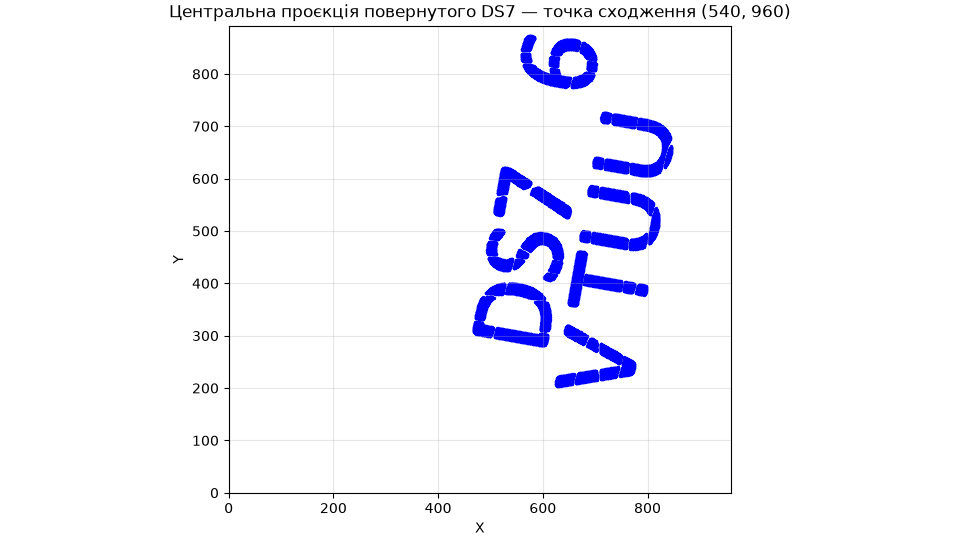

In [ ]:
from pathlib import Path
import math
import matplotlib.pyplot as plt

# Підтримуємо запуск із папки лабораторної або кореня репозиторію.
root = Path.cwd()
if not (root / "лабораторна робота 2").is_dir():
    root = root.parent

input_path = root / "лабораторна робота 3" / "transformed_DS7.txt"
output_dir = root / "лабораторна робота 4"
if not input_path.is_file():
    raise FileNotFoundError("Спочатку виконайте лабораторну № 3 для створення transformed_DS7.txt.")
points = []
with input_path.open(encoding="utf-8") as file:
    for line in file:
        if line.strip() and not line.lstrip().startswith("#"):
            x, y = map(float, line.split())
            points.append((x, y))

z_val = 100.0
xc, yc = 540.0, 960.0
# Додатковий параметр моделі, оскільки умова не задає фокусної відстані.
# Центр проєкції C=(xc, yc, -d), площина зображення z=0.
d = 500.0
# Матриця для вектора-стовпця (x, y, z, 1).
projection_matrix = [
    [d, 0.0, xc, 0.0],
    [0.0, d, yc, 0.0],
    [0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, d],
]
print("Матриця центральної проєкції:")
for row in projection_matrix:
    print(" ".join(f"{value:10.3f}" for value in row))
print(f"Центр проєкції C=({xc:g}, {yc:g}, {-d:g}); площина z=0.")

projected_points = []
for x, y in points:
    source = (x, y, z_val, 1.0)
    homogeneous = [
        sum(value * coordinate for value, coordinate in zip(row, source))
        for row in projection_matrix
    ]
    projected_points.append((
        homogeneous[0] / homogeneous[3],
        homogeneous[1] / homogeneous[3],
    ))

with (output_dir / "projected_DS7.txt").open("w", encoding="utf-8") as file:
    file.write(f"# Projection of lab 3 DS7; z={z_val}; d={d}\n")
    for x, y in projected_points:
        file.write(f"{x:.12f} {y:.12f}\n")

xs = [x for x, y in projected_points]
ys = [y for x, y in projected_points]
fig, ax = plt.subplots(figsize=(9.6, 5.4), dpi=100, layout="constrained")
ax.scatter(xs, ys, color="blue", s=2)
# Показуємо всі точки без обрізання, зберігаючи полотно 960 × 540 пкс.
ax.set_xlim(min(0, min(xs) - 20), max(960, max(xs) + 20))
ax.set_ylim(min(0, min(ys) - 20), max(540, max(ys) + 20))
ax.set_aspect("equal", adjustable="box")
ax.set(xlabel="X", ylabel="Y",
       title="Центральна проєкція повернутого DS7 — точка сходження (540, 960)")
ax.grid(True, alpha=0.3)
fig.savefig(output_dir / "central_projection_result.png", dpi=100)
plt.show()
print(f"Спроєктовано {len(projected_points)} точок із лабораторної № 3.")
print("Збережено central_projection_result.png (960 × 540 пкс).")




## Модель проєкції

Спочатку потрібно виконати лабораторну № 3. Вхідні дані — її файл transformed_DS7.txt, z = 100. Обрано центр проєкції C = (540, 960, −500) та площину зображення z = 0. Значення d = 500 є додатковим припущенням, оскільки умова його не задає. Формули x′ = (d x + xc z)/(d + z), y′ = (d y + yc z)/(d + z) реалізовано через однорідну матрицю 4 × 4 із діленням на четверту координату. Межі осей охоплюють усі точки, а PNG має 960 × 540 пікселів. Результуючі координати записуються у projected_DS7.txt.